# Reaction scheme for the DES lignin pathway model
Each reaction coded in `utils/desl_lignin_pathways.py` is applied to a small model compound with the script's own `apply_acidolysis`, so the drawn products are exactly what the code produces.

Ring openings (1-3) add one water. The ring-opening rules, route weights and the vanillin-type and no-γ routes are  scenario settings, not established DES chemistry.

In [ ]:
from IPython.display import display
from utils.draw_reaction_scheme import REACTIONS, reaction_image, reaction_label, build_figure

## Workflow of the simulation model

1. **Input:** a lignin SMILES string, plus the user-set cleavage fractions, β-O-4 route ratios and a random seed.
2. **Substructure matching:** SMARTS patterns find β-O-4 units and the α-O-4 ethers (acyclic, DBDO-like rings, phenylcoumaran rings).
3. **Optional hydrolyses (steps 1-3):** each adds one water to a user-set fraction of the matching sites (off by default).
4. **β-O-4 cleavage (step 4):** a user-set fraction of units is cleaved. Each cleaved unit is assigned by a seeded random draw to the Hibbert-ketone, C2-aldehyde or vanillin-type route.
5. **β-O-4 without γ-CH2OH (step 5):** applies to model compounds only as the larger lignin datast do no have this structure.
6. **Mass-balance check** after every reaction event.
7. **Fractionation and descriptors:** an optional molecular-weight cutoff (`--min-precipitate-mw`, 50 Da in the example below) splits the fragments into a precipitated (DESL) and a soluble fraction; formula-based Mn, Mw and PDI, functional-group counts and total OH are reported for each.

### Worked example: the DP = 4 structure

The script is run on a DP = 4 lignin model (resinol unit + two beta-O-4 units). The route weights and seed are set so that one Hibbert and one vanillin-type event occur, to show both. Cleavage conserves mass, so the fragment total equals the input; the averages fall because one chain becomes several molecules.

A 50 Da cutoff is then applied: fragments of at least 50 Da count as the precipitated fraction, so only formaldehyde (30) and acetaldehyde (44) move to the soluble fraction. The cutoff is illustrative and not experimentally calibrated.

Stage 1  Input        : mass 750.3  Mn 750.3  Mw 750.3  PDI 1.00
         groups       : {'carbonyl': 0, 'phenolicOH': 2, 'aliphaticOH_primary': 2, 'aliphaticOH_secondary': 2}
Stage 2  beta-O-4 sites found: 2   cleaved: 2   (Hibbert 1, C2-aldehyde 0, vanillin-type 1)
Stage 3  Ring hydrolyses     : none requested (fractions 0), no water added
Stage 4  Output       : 4 fragments, total mass 750.3  Mn 187.6  Mw 255.6  PDI 1.36
         groups       : {'carbonyl': 3, 'phenolicOH': 4, 'aliphaticOH_primary': 1, 'aliphaticOH_secondary': 0}
Stage 5  Cutoff 50 Da : precipitated 3 fragments, mass 706.3  Mn 235.4  Mw 268.8  PDI 1.14; soluble 1 (['CC=O'])
         recovered mass fraction: 94.1% (illustrative)
         total without acetaldehyde: 706.3


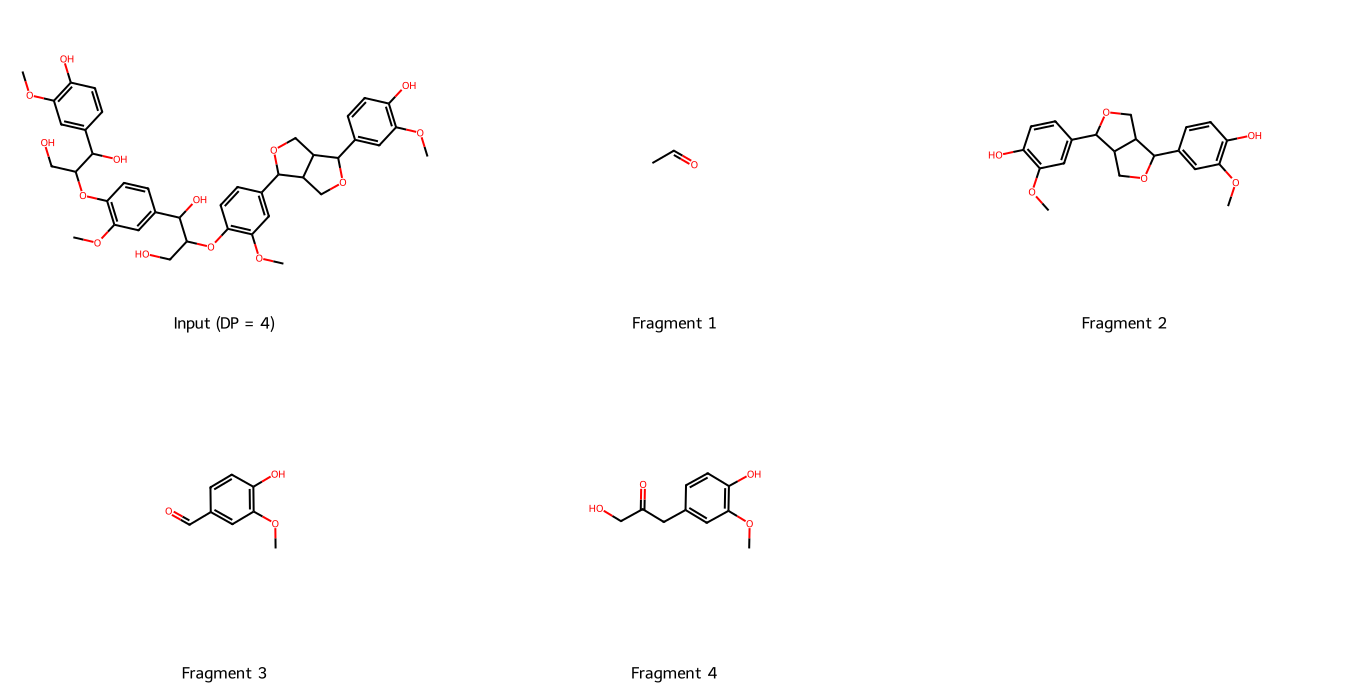

In [4]:
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw
from utils.desl_lignin_pathways import apply_acidolysis, summarize_fragments
from utils.desl_simulation import find_functional_groups_counts

dp4 = 'COc1cc(ccc1O)C1OCC2C1COC2c1ccc(OC(CO)C(O)c3ccc(OC(CO)C(O)c4ccc(O)c(OC)c4)c(OC)c3)c(OC)c1'
keys = ['carbonyl', 'phenolicOH', 'aliphaticOH_primary', 'aliphaticOH_secondary']

result = apply_acidolysis(dp4, cleavage_fraction=1.0, route_weights=(0.5, 0.0, 0.5), random_seed=1)
fragments = list(result[0][0])
inp = summarize_fragments([dp4])
out = summarize_fragments(fragments)

# Optional fractionation (--min-precipitate-mw): at or above the cutoff = precipitated (DESL)
min_precipitate_mw = 50
mass = lambda f: Descriptors.ExactMolWt(Chem.MolFromSmiles(f))
precipitated = [f for f in fragments if mass(f) >= min_precipitate_mw]
soluble = [f for f in fragments if mass(f) < min_precipitate_mw]
prec = summarize_fragments(precipitated)

print(f"Stage 1  Input        : mass {inp['total_mass']:.1f}  Mn {inp['Mn']:.1f}  Mw {inp['Mw']:.1f}  PDI {inp['PDI']:.2f}")
print(f"         groups       : { {k: find_functional_groups_counts(dp4)[k] for k in keys} }")
print(f"Stage 2  beta-O-4 sites found: {result[1]}   cleaved: {result[2]}   (Hibbert {result[4]}, C2-aldehyde {result[11]}, vanillin-type {result[3]})")
print(f"Stage 3  Ring hydrolyses     : none requested (fractions 0), no water added")
print(f"Stage 4  Output       : {len(fragments)} fragments, total mass {out['total_mass']:.1f}  Mn {out['Mn']:.1f}  Mw {out['Mw']:.1f}  PDI {out['PDI']:.2f}")
print(f"         groups       : { {k: find_functional_groups_counts('.'.join(fragments))[k] for k in keys} }")
print(f"Stage 5  Cutoff {min_precipitate_mw} Da : precipitated {len(precipitated)} fragments, mass {prec['total_mass']:.1f}  Mn {prec['Mn']:.1f}  Mw {prec['Mw']:.1f}  PDI {prec['PDI']:.2f}; soluble {len(soluble)} ({[f for f in soluble]})")
print(f"         recovered mass fraction: {prec['total_mass'] / out['total_mass']:.1%} (illustrative)")
print(f"         total without acetaldehyde: {out['total_mass'] - Descriptors.ExactMolWt(Chem.MolFromSmiles('CC=O')):.1f}")

mols = [Chem.MolFromSmiles(dp4)] + [Chem.MolFromSmiles(f) for f in fragments]
Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(450, 350),
                     legends=['Input (DP = 4)'] + [f'Fragment {i + 1}' for i in range(len(fragments))])

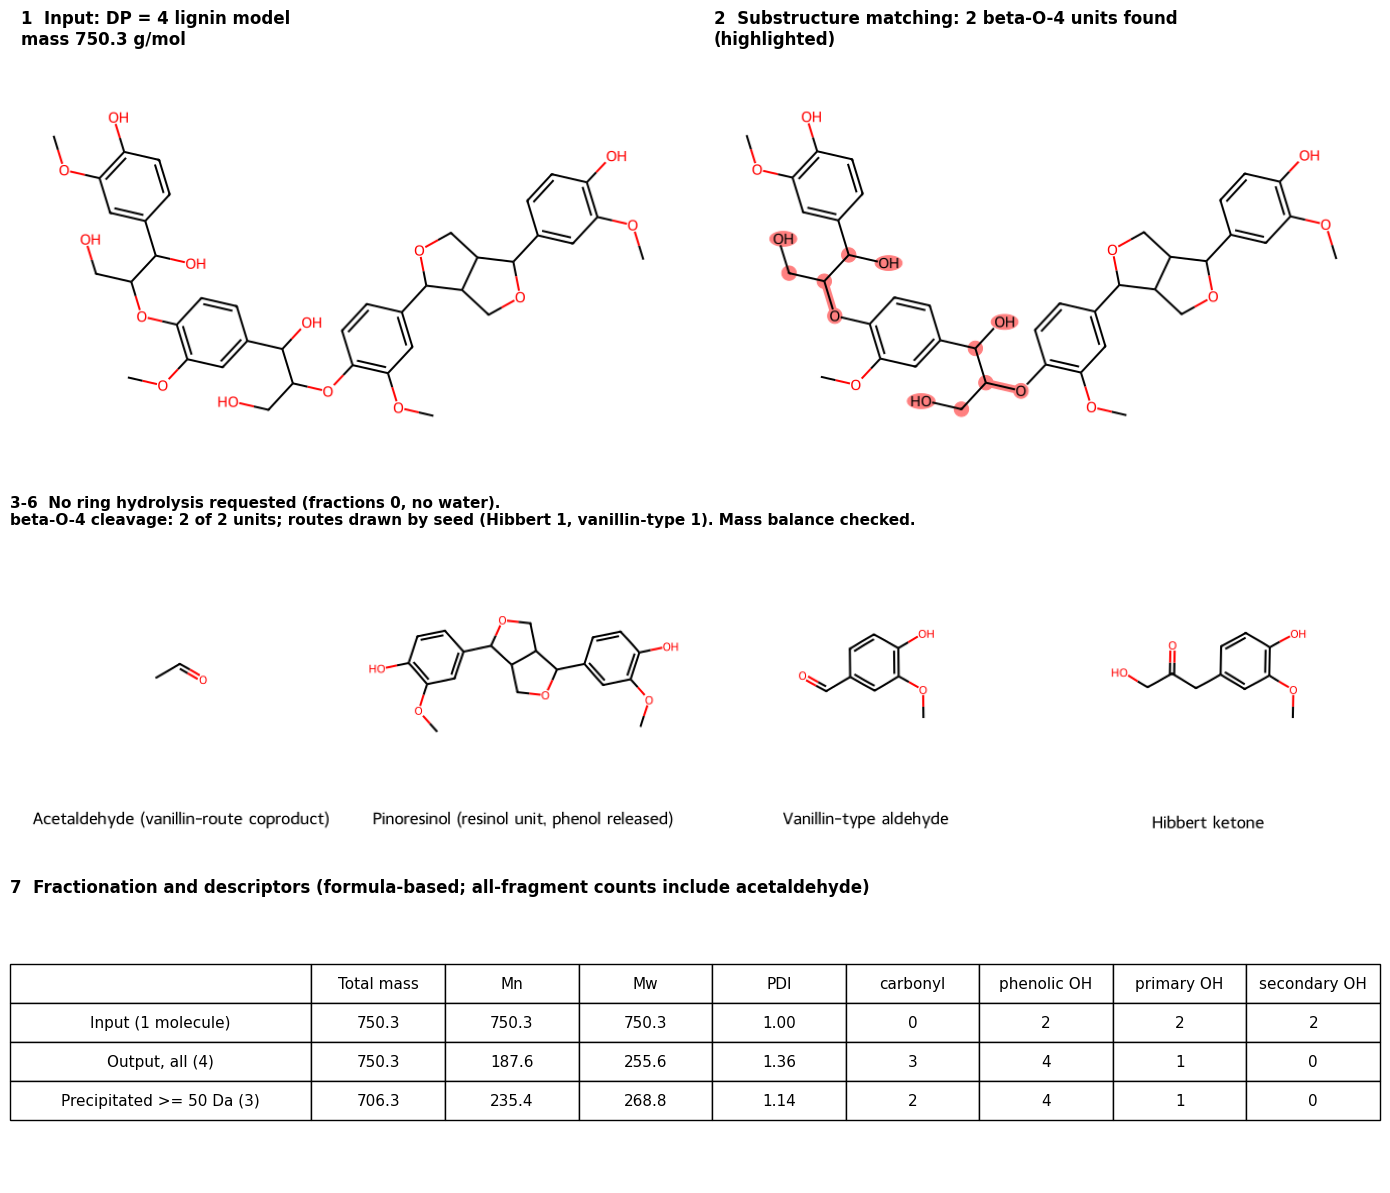

In [8]:
# Stage-by-stage view for the same DP = 4 compound
names = {
    Chem.CanonSmiles('CC=O'): 'Acetaldehyde (vanillin-route coproduct)',
    Chem.CanonSmiles('COc1cc(C2OCC3C(c4ccc(O)c(OC)c4)OCC23)ccc1O'): 'Pinoresinol (resinol unit, phenol released)',
    Chem.CanonSmiles('COc1cc(C=O)ccc1O'): 'Vanillin-type aldehyde',
    Chem.CanonSmiles('COc1cc(CC(=O)CO)ccc1O'): 'Hibbert ketone',
}
import io
from PIL import Image

def to_pil(img):
    """RDKit returns a PIL image or an IPython PNG object depending on the environment."""
    return img if isinstance(img, Image.Image) else Image.open(io.BytesIO(img.data))

mol_in = Chem.MolFromSmiles(dp4)

# Stage 2: highlight the beta-O-4 units that the template matches
query = Chem.MolFromSmarts('[c:1]-[CH:2]([OH:3])-[CH:4]([O:5]-[c:6])-[CH2:7][OH:8]')
hit_atoms, hit_bonds = set(), set()
for match in mol_in.GetSubstructMatches(query):
    hit_atoms.update(match[1:5] + match[6:8])           # C-alpha, OH, C-beta, ether O, C-gamma, OH
    hit_bonds.add(mol_in.GetBondBetweenAtoms(match[3], match[4]).GetIdx())   # the C-beta-O ether bond
img_in = Draw.MolToImage(mol_in, size=(650, 420))
img_hit = Draw.MolToImage(mol_in, size=(650, 420), highlightAtoms=sorted(hit_atoms), highlightBonds=sorted(hit_bonds))
img_out = to_pil(Draw.MolsToGridImage([Chem.MolFromSmiles(f) for f in fragments], molsPerRow=4, subImgSize=(330, 300),
                               legends=[names.get(Chem.CanonSmiles(f), 'Fragment') for f in fragments]))

fig = plt.figure(figsize=(14, 12))
grid = fig.add_gridspec(3, 2, height_ratios=[1.2, 1.0, 0.8])
panels = [(grid[0, 0], img_in, '1  Input: DP = 4 lignin model\nmass %.1f g/mol' % inp['total_mass']),
          (grid[0, 1], img_hit, '2  Substructure matching: %d beta-O-4 units found\n(highlighted)' % result[1])]
for spec, image, title in panels:
    ax = fig.add_subplot(spec); ax.imshow(image); ax.set_title(title, loc='left', fontsize=12, fontweight='bold'); ax.axis('off')
ax = fig.add_subplot(grid[1, :]); ax.imshow(img_out); ax.axis('off')
ax.set_title('3-6  No ring hydrolysis requested (fractions 0, no water).\nbeta-O-4 cleavage: %d of %d units; routes drawn by seed '
             '(Hibbert %d, vanillin-type %d). Mass balance checked.' % (result[2], result[1], result[4], result[3]),
             loc='left', fontsize=11, fontweight='bold')
ax = fig.add_subplot(grid[2, :]); ax.axis('off')
rows = [['', 'Total mass', 'Mn', 'Mw', 'PDI', 'carbonyl', 'phenolic OH', 'primary OH', 'secondary OH'],
        ['Input (1 molecule)', '%.1f' % inp['total_mass'], '%.1f' % inp['Mn'], '%.1f' % inp['Mw'], '%.2f' % inp['PDI']] + [find_functional_groups_counts(dp4)[k] for k in keys],
        ['Output, all (%d)' % len(fragments), '%.1f' % out['total_mass'], '%.1f' % out['Mn'], '%.1f' % out['Mw'], '%.2f' % out['PDI']] + [find_functional_groups_counts('.'.join(fragments))[k] for k in keys],
        ['Precipitated >= %g Da (%d)' % (min_precipitate_mw, len(precipitated)), '%.1f' % prec['total_mass'], '%.1f' % prec['Mn'], '%.1f' % prec['Mw'], '%.2f' % prec['PDI']] + [find_functional_groups_counts('.'.join(precipitated))[k] for k in keys]]
table = ax.table(cellText=rows[1:], colLabels=rows[0], loc='center', cellLoc='center', colWidths=[0.22] + [0.0975] * 8)
table.auto_set_font_size(False); table.set_fontsize(11); table.scale(1, 1.8)
ax.set_title('7  Fractionation and descriptors (formula-based; all-fragment counts include acetaldehyde)', loc='left', fontsize=12, fontweight='bold')
fig.tight_layout()
fig.savefig('image/workflow_dp4.png', dpi=300)
plt.show()

In [10]:
# One reaction at a time
for index, (title, reactant, kwargs, uses_water) in enumerate(REACTIONS):
    print(reaction_label(index))
    display(reaction_image(reactant, uses_water, kwargs))

NameError: name 'REACTIONS' is not defined

In [7]:
# All reactions in one figure (also saved for the paper)
figure = build_figure()
figure.savefig('image/reaction_scheme.png', dpi=300)
figure

NameError: name 'build_figure' is not defined